# 04 · Face detection and the real-time pieces

**Read first:** `01_theory/07_detection_realtime.md`

1. the integral image — any rectangle sum with 4 reads
2. the cascade arithmetic
3. Haar detection on a "photo", with `minNeighbors` and the crop with a margin
4. the pre-processing pipeline — **identical** in training and in real time
5. temporal smoothing: averaging probability vectors stops the flicker
6. the camera thread: "latest frame only", with a lock and a copy

In [1]:
import threading
import time
from collections import deque
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

## 1. The integral image

In [2]:
img = np.array([[1, 2, 3], [4, 5, 6], [7, 8, 9]])
I = img.cumsum(0).cumsum(1)
print(I)
# rectangle rows 1..2, cols 1..2  ->  I(D) - I(B) - I(C) + I(A)
print("sum of [5 6; 8 9] =", I[2, 2] - I[0, 2] - I[2, 0] + I[0, 0], "  check:", img[1:, 1:].sum())
print("OpenCV agrees:", (cv2.integral(img.astype(np.uint8))[1:, 1:] == I).all())

[[ 1  3  6]
 [ 5 12 21]
 [12 27 45]]
sum of [5 6; 8 9] = 28   check: 28
OpenCV agrees: True


## 2. Why the cascade is fast

In [3]:
print(f"faces surviving 22 stages of 99.5%: {0.995 ** 22:.2f}")
print(f"non-faces surviving 22 stages of 50%: {0.5 ** 22:.1e}  -> x 100,000 windows = {100_000 * 0.5 ** 22:.2f} false detections per frame")

faces surviving 22 stages of 99.5%: 0.90
non-faces surviving 22 stages of 50%: 2.4e-07  -> x 100,000 windows = 0.02 false detections per frame


## 3. Haar on FER faces — and why the crop matters

FER-2013 faces are cropped **tightly**: no forehead, no chin, no background. The Haar cascade was trained on faces
*with* some surroundings. Measure it: how many of 120 test faces does it find, as they are and with a 30% border?

In [4]:
ROOT = Path("../data/fer2013/test")
cascade = cv2.CascadeClassifier(cv2.data.haarcascades + "haarcascade_frontalface_default.xml")

def bordered(img, frac=0.3):
    p = int(img.shape[0] * frac)
    return cv2.copyMakeBorder(img, p, p, p, p, cv2.BORDER_REPLICATE)

def detected(img):
    big = cv2.resize(img, (200, 200), interpolation=cv2.INTER_CUBIC)
    return len(cascade.detectMultiScale(big, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))) > 0

sample = [cv2.imread(str(f), 0) for e in ("happy", "surprise", "neutral") for f in sorted((ROOT / e).iterdir())[:40]]
print(f"tight crop    : {sum(detected(f) for f in sample)} of {len(sample)} found")
print(f"with a border : {sum(detected(bordered(f)) for f in sample)} of {len(sample)} found")

tight crop    : 71 of 120 found


with a border : 95 of 120 found


The border helps a lot; the faces still missed are mostly turned sideways, covered by a hand, or very blurry —
exactly the cases where the DNN detector (stage 7 of your project) does better.

Now a "photo": three bordered faces on a 640×360 grey background (we take the first face of each emotion that the
detector finds on its own, starting at file 5).

minNeighbors=1: 3 detections in 26.2 ms
minNeighbors=5: 3 detections in 24.3 ms


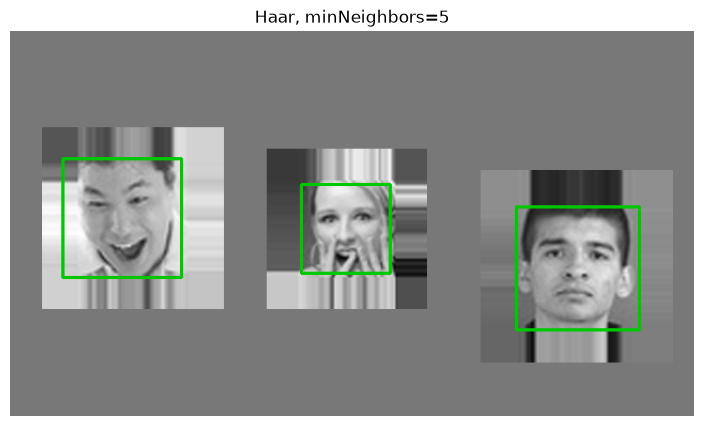

In [5]:
scene = np.full((360, 640), 120, np.uint8)
truth = []
for i, (emotion, x0, size) in enumerate((("happy", 30, 170), ("surprise", 240, 150), ("neutral", 440, 180))):
    files = sorted((ROOT / emotion).iterdir())[5:]
    face = next(bordered(img) for img in (cv2.imread(str(f), 0) for f in files) if detected(bordered(img)))
    face = cv2.resize(face, (size, size), interpolation=cv2.INTER_CUBIC)
    y0 = 90 + 20 * i
    scene[y0:y0 + size, x0:x0 + size] = face
    truth.append(emotion)

for neighbours in (1, 5):
    t0 = time.perf_counter()
    found = cascade.detectMultiScale(scene, scaleFactor=1.1, minNeighbors=neighbours, minSize=(60, 60))
    print(f"minNeighbors={neighbours}: {len(found)} detections in {(time.perf_counter() - t0) * 1000:.1f} ms")

shown = cv2.cvtColor(scene, cv2.COLOR_GRAY2RGB)
for (x, y, w, h) in found:
    cv2.rectangle(shown, (x, y), (x + w, y + h), (0, 200, 0), 2)
plt.figure(figsize=(9, 5)); plt.imshow(shown); plt.axis("off"); plt.title("Haar, minNeighbors=5"); plt.show()

## 4. Crop with a margin → the SAME pre-processing as training

The detector's box is tight; FER faces include a bit of forehead and chin. Add a margin, clip to the image, then
grey → 48×48 → equalise → /255 → normalise with the training mean and std — **every step identical to training**.

In [6]:
def with_margin(box, margin, shape):
    x, y, w, h = box
    dx, dy = int(w * margin), int(h * margin)
    x0, y0 = max(0, x - dx), max(0, y - dy)
    x1, y1 = min(shape[1], x + w + dx), min(shape[0], y + h + dy)
    return x0, y0, x1, y1

def preprocess(gray_crop):
    # MUST be exactly what the model saw in training: notebook 03 equalised every face, so we do too.
    face = cv2.resize(gray_crop, (48, 48), interpolation=cv2.INTER_AREA)
    face = cv2.equalizeHist(face)
    x = face.astype(np.float32) / 255.0
    x = (x - 0.5013) / 0.2916                               # the TRAINING numbers - never recompute here
    return torch.from_numpy(x)[None, None]                  # (1, 1, 48, 48)

# the small model trained in notebook 03
def conv_bn(c_in, c_out, stride):
    return nn.Sequential(nn.Conv2d(c_in, c_out, 3, stride, 1, bias=False), nn.BatchNorm2d(c_out), nn.ReLU())
class SmallNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(conv_bn(1, 32, 2), conv_bn(32, 64, 1), conv_bn(64, 128, 2), conv_bn(128, 256, 2))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.3), nn.Linear(256, 7))
    def forward(self, x):
        return self.head(self.features(x))

EMOTIONS = ["angry", "disgust", "fear", "happy", "neutral", "sad", "surprise"]
model = SmallNet()
model.load_state_dict(torch.load("../data/_smallnet.pt"))
model.eval()                                                # never forget

for box in sorted(found, key=lambda b: b[0]):
    x0, y0, x1, y1 = with_margin(box, 0.1, scene.shape)
    with torch.no_grad():
        p = torch.softmax(model(preprocess(scene[y0:y1, x0:x1])), 1)[0].numpy()
    print(f"face at x={box[0]:3d}: {EMOTIONS[p.argmax()]:9s} {p.max():.0%}")
print("truth, left to right:", truth)

face at x= 49: disgust   23%
face at x=272: surprise  53%
face at x=473: neutral   37%
truth, left to right: ['happy', 'surprise', 'neutral']


The small CPU model of notebook 03 is right only ~4 times in 10, so three faces prove nothing either way — your GPU
EmotionNet is the real thing. Measure instead: for every test face the detector finds, is the model right on the
**original** 48×48 image, and on the crop that came through the **pipeline** (border → enlarge → detect → margin →
crop → resize)?

In [7]:
def classify(gray):
    with torch.no_grad():
        return EMOTIONS[model(preprocess(gray)).argmax().item()]

print(f"{'':9s} {'detected':>8s} {'right on original':>18s} {'right via pipeline':>19s}")
for emotion in ("happy", "surprise", "neutral"):
    n = raw_ok = pipe_ok = 0
    for f in sorted((ROOT / emotion).iterdir())[:60]:
        img = cv2.imread(str(f), 0)
        big = cv2.resize(bordered(img), (200, 200), interpolation=cv2.INTER_CUBIC)
        boxes = cascade.detectMultiScale(big, scaleFactor=1.1, minNeighbors=5, minSize=(60, 60))
        if len(boxes) == 0:
            continue
        x0, y0, x1, y1 = with_margin(boxes[0], 0.1, big.shape)
        n += 1
        raw_ok += classify(img) == emotion
        pipe_ok += classify(big[y0:y1, x0:x1]) == emotion
    print(f"{emotion:9s} {n:8d} {raw_ok:18d} {pipe_ok:19d}")

          detected  right on original  right via pipeline


happy           50                 34                  29


surprise        47                 35                  34


neutral         44                 32                  20


For happy and surprise the pipeline loses little. For neutral it loses more: the crop is framed differently from the
FER crops the model learned from (a bit more or less forehead, chin, background). **Framing is part of
pre-processing** — another face of train/serve skew, and the reason `FACE_MARGIN` exists in your config. Try
margins of 0.0, 0.1 and 0.2 below and see which one matches the training framing best.

## 5. Temporal smoothing — average the vectors, then argmax

A borderline expression (happy 0.51 / neutral 0.49) flips the label with every bit of noise. We simulate 60 frames
of exactly that and compare the raw labels with a moving average over the last 5 probability vectors.

label changes in 60 frames: raw 16   smoothed 8


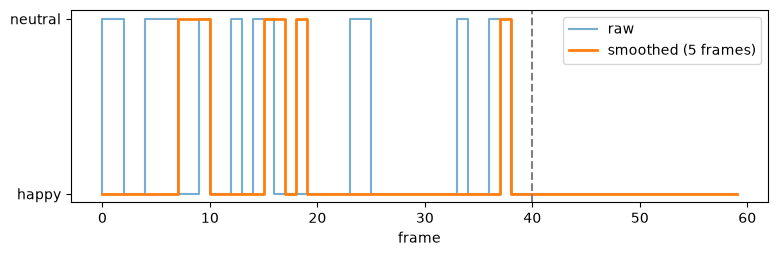

In [8]:
class TemporalSmoother:
    def __init__(self, window=5):
        self.window = deque(maxlen=window)
    def update(self, probs):
        self.window.append(probs)
        avg = np.mean(self.window, axis=0)
        return int(avg.argmax()), float(avg.max())

rng = np.random.default_rng(0)
base = np.array([0, 0, 0, 0.51, 0.49, 0, 0])
raw_labels, smooth_labels, sm = [], [], TemporalSmoother(5)
for t in range(60):
    p = np.clip(base + rng.normal(0, 0.04, 7), 0, None); p /= p.sum()
    if t >= 40:                                  # the person really starts smiling at frame 40
        p = np.array([0, 0, 0, 0.8, 0.2, 0, 0])
    raw_labels.append(p.argmax()); smooth_labels.append(sm.update(p)[0])

changes = lambda seq: sum(a != b for a, b in zip(seq, seq[1:]))
print(f"label changes in 60 frames: raw {changes(raw_labels)}   smoothed {changes(smooth_labels)}")
plt.figure(figsize=(9, 2.5))
plt.step(range(60), [EMOTIONS[i] for i in raw_labels], label="raw", alpha=.6)
plt.step(range(60), [EMOTIONS[i] for i in smooth_labels], label="smoothed (5 frames)", lw=2)
plt.axvline(40, ls="--", c="gray"); plt.legend(); plt.xlabel("frame"); plt.show()

Fewer flips — and with a longer window, fewer still — while a real change (frame 40) is still followed within a few
frames. The window size is a trade-off between calm and responsive; your config uses 5.

## 6. The camera thread — "latest frame only"

`cap.read()` blocks for 30–40 ms. A background thread reads frames forever and keeps only the latest; the GUI takes
"whatever is there now". A lock, and a **copy** on read. Here a fake camera produces numbered frames at 30 FPS
while a slow "GUI" processes at ~12 FPS:

In [9]:
class LatestFrame:
    def __init__(self):
        self._lock, self._frame, self.running = threading.Lock(), None, True
    def camera_loop(self):
        n = 0
        while self.running:
            time.sleep(1 / 30)                              # cap.read() waiting for the camera
            n += 1
            frame = np.full((4, 4), n, np.int32)
            with self._lock:
                self._frame = frame
    def read(self):
        with self._lock:
            return None if self._frame is None else self._frame.copy()

cam = LatestFrame()
threading.Thread(target=cam.camera_loop, daemon=True).start()
seen = []
t_end = time.perf_counter() + 1.0
while time.perf_counter() < t_end:
    f = cam.read()
    if f is not None:
        seen.append(int(f[0, 0]))
    time.sleep(1 / 12)                                      # detection + inference + drawing
cam.running = False
print("frames the GUI processed:", seen)
print("the GUI never fell behind: it always took the newest frame and skipped the rest")

frames the GUI processed: [2, 4, 7, 9, 12, 14, 17, 19, 22, 24, 27]
the GUI never fell behind: it always took the newest frame and skipped the rest


## ✍️ Try it yourself

1. Compute the integral image of a 4×4 matrix by hand and the sum of the central 2×2 with 4 reads.
2. Change `minNeighbors` to 1, 3, 8 and `scaleFactor` to 1.3. What do you gain and what do you lose?
3. Normalise the camera crop with the crop's **own** mean and std instead of 0.5013 / 0.2916. Do the predictions
   change? This is train/serve skew.
4. In the measurement cell, try margins 0.0, 0.1, 0.2. Which gives the most correct answers via the pipeline?

Then solve exercises 11–12 in `03_exercises/`.